# Task 1: Data Exploration
This section explores the breast cancer dataset using visualization, normalization, and PCA.

In [1]:
# STEP 1: LOAD & PREPARE DATA

# Import libraries
import pandas as pd
import kagglehub
import os

# Download dataset using kagglehub
path = kagglehub.dataset_download("ahmeduzaki/diagnostic-breast-cancer-dataset")

print("Dataset downloaded to:", path)

# Check files inside folder
files = os.listdir(path)
print("Files in dataset:", files)

# Load the dataset (take first file)
file_path = os.path.join(path, files[0])
data = pd.read_csv(file_path)

# Show first rows to understand structure
print("\nFirst 5 rows:")
print(data.head())

# Dataset info (columns, types, nulls)
print("\nDataset Info:")
print(data.info())

# Clean dataset (remove unnecessary columns if exist)
if 'ID' in data.columns:
    data = data.drop('ID', axis=1)

# Separate features (X) and labels (y)
y = data['Diagnosis']          # Target column
X = data.drop('Diagnosis', axis=1)  # Features

# Show shapes
print("\nFeatures shape:", X.shape)
print("Labels shape:", y.shape)

100%|██████████| 49.1k/49.1k [00:00<00:00, 1.06MB/s]

Extracting files...
Dataset downloaded to: /root/.cache/kagglehub/datasets/ahmeduzaki/diagnostic-breast-cancer-dataset/versions/1
Files in dataset: ['Diagnostic Breast Cancer Dataset.csv']

First 5 rows:
         ID  Mean Radius  Mean Texture  Mean Perimeter  Mean Area  \
0    842302        17.99         10.38          122.80     1001.0   
1    842517        20.57         17.77          132.90     1326.0   
2  84300903        19.69         21.25          130.00     1203.0   
3  84348301        11.42         20.38           77.58      386.1   
4  84358402        20.29         14.34          135.10     1297.0   

   Mean Smoothness  Mean Compactness  Mean Concavity  Mean Concave Points  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520

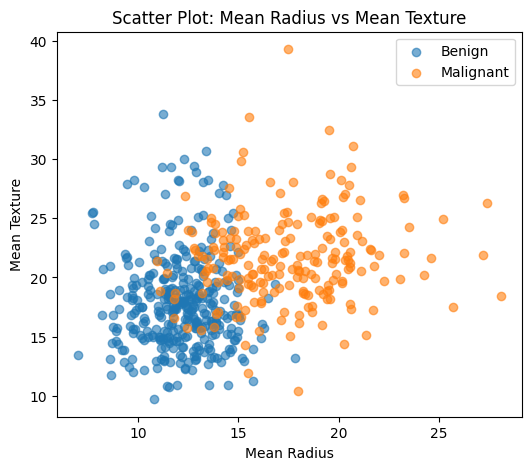

In [2]:
# STEP 2: SCATTER PLOT

import matplotlib.pyplot as plt

# Select two features
feature1 = 'Mean Radius'
feature2 = 'Mean Texture'

# Create scatter plot
plt.figure(figsize=(6,5))

# Plot Benign cases
plt.scatter(
    X[y == 'Benign'][feature1],
    X[y == 'Benign'][feature2],
    label='Benign',
    alpha=0.6
)

# Plot Malignant cases
plt.scatter(
    X[y == 'Malignant'][feature1],
    X[y == 'Malignant'][feature2],
    label='Malignant',
    alpha=0.6
)

# Labels and title
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title("Scatter Plot: Mean Radius vs Mean Texture")

plt.legend()

# Show plot
plt.show()

In [3]:
# STEP 3: DATA NORMALIZATION


from sklearn.preprocessing import StandardScaler
import pandas as pd

# Initialize scaler
scaler = StandardScaler()

# Fit and transform features
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame for easier handling
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

# Show first rows
X_scaled.head()

,Mean Radius,Mean Texture,Mean Perimeter,Mean Area,Mean Smoothness,Mean Compactness,Mean Concavity,Mean Concave Points,Mean Symmetry,Mean Fractal Dimension,...,Worst Radius,Worst Texture,Worst Perimeter,Worst Area,Worst Smoothness,Worst Compactness,Worst Concavity,Worst Concave Points,Worst Symmetry,Worst Fractal Dimension
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,...,1.886690,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,...,1.805927,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,...,1.511870,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,...,-0.281464,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,...,1.298575,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100


In [4]:
# Mean & Std of first feature in normalized data

first_feature = X_scaled.columns[0]
print("First feature:", first_feature)
print("Mean:", round(X_scaled[first_feature].mean(), 6))
print("Standard Deviation:", round(X_scaled[first_feature].std(), 6))

First feature: Mean Radius
Mean: -0.0
Standard Deviation: 1.00088


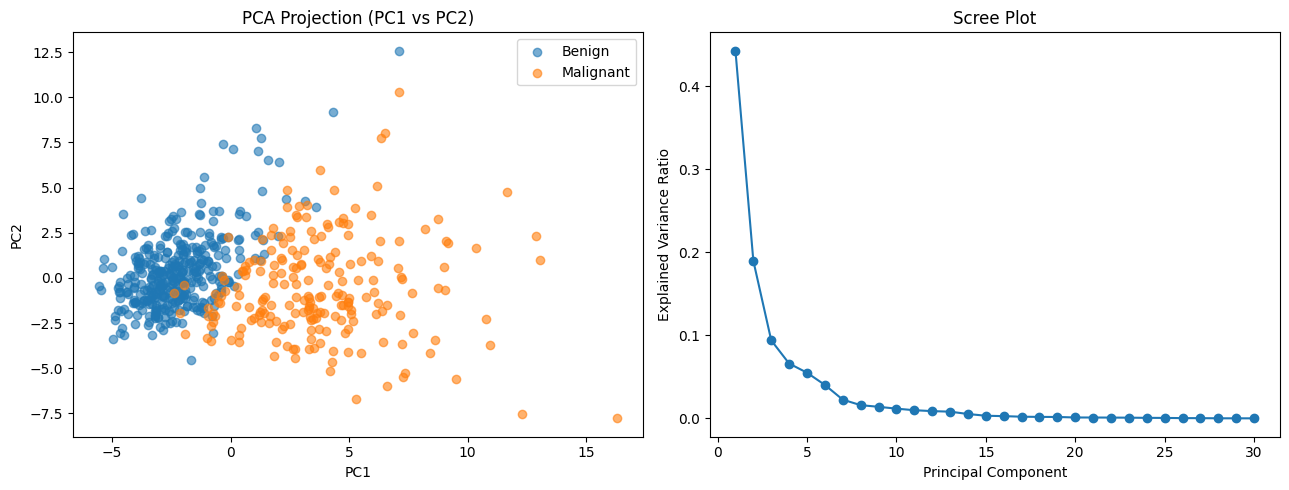

In [5]:
# STEP 4: APPLY PCA


from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

# Apply PCA on normalized data
pca = PCA()
X_pca = pca.fit_transform(X_scaled)


# Combined Figure: Scree Plot + PCA Projection


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: PCA Projection (PC1 vs PC2)
pca_df = pd.DataFrame(X_pca[:, :2], columns=['PC1', 'PC2'])
pca_df['Diagnosis'] = y.values

axes[0].scatter(
    pca_df[pca_df['Diagnosis'] == 'Benign']['PC1'],
    pca_df[pca_df['Diagnosis'] == 'Benign']['PC2'],
    label='Benign', alpha=0.6
)
axes[0].scatter(
    pca_df[pca_df['Diagnosis'] == 'Malignant']['PC1'],
    pca_df[pca_df['Diagnosis'] == 'Malignant']['PC2'],
    label='Malignant', alpha=0.6
)
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("PCA Projection (PC1 vs PC2)")
axes[0].legend()

# Subplot 2: Scree Plot
axes[1].plot(range(1, len(pca.explained_variance_ratio_) + 1),
             pca.explained_variance_ratio_, marker='o')
axes[1].set_title("Scree Plot")
axes[1].set_xlabel("Principal Component")
axes[1].set_ylabel("Explained Variance Ratio")

plt.tight_layout()
plt.show()

# Task 2: Data Preparation

In this task, the dataset is split into training and testing sets using an 80%-20% ratio.

In [6]:
# TASK 2: PROPER SCALING (fit on train only)


from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# First split the RAW (unscaled) data
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,               # use original unscaled X
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit scaler ONLY on training set, then transform both
scaler2 = StandardScaler()
X_train = pd.DataFrame(scaler2.fit_transform(X_train_raw), columns=X.columns)
X_test  = pd.DataFrame(scaler2.transform(X_test_raw),      columns=X.columns)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (455, 30)
Testing set size: (114, 30)


# Task 3: Data Classification without Feature Reduction

In this task, classification models are built using the original normalized features without applying PCA. The performance of SVM and K-NN models is evaluated using multiple metrics.

## 3.1 Support Vector Machine (SVM)

SVM models are built using both linear and RBF kernels. Different parameter values are tested to determine the best-performing model.

In [7]:
# SVM SETUP


from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Function to evaluate model
def evaluate_model(y_test, y_pred):
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label='Malignant', zero_division=0)
    rec = recall_score(y_test, y_pred, pos_label='Malignant', zero_division=0)
    f1 = f1_score(y_test, y_pred, pos_label='Malignant', zero_division=0)

    return acc, prec, rec, f1

In [8]:
# Linear Kernel
# The SVM model is tested using a linear kernel with different values of the regularization parameter C.


C_values = [2, 10, 50]

for C in C_values:
    model = SVC(kernel='linear', C=C)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    acc, prec, rec, f1 = evaluate_model(y_test, y_pred)

    print(f"\nLinear SVM (C={C})")
    print("Accuracy:", acc)
    print("Precision:", prec)
    print("Recall:", rec)
    print("F1 Score:", f1)


Linear SVM (C=2)
Accuracy: 0.9649122807017544
Precision: 1.0
Recall: 0.9047619047619048
F1 Score: 0.95

Linear SVM (C=10)
Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1 Score: 0.9629629629629629

Linear SVM (C=50)
Accuracy: 0.9298245614035088
Precision: 0.925
Recall: 0.8809523809523809
F1 Score: 0.9024390243902439


In [9]:
# RBF Kernel
# The SVM model is tested using the RBF kernel with different combinations of C and gamma values.


C_values = [2, 10, 50]
gamma_values = [0.01, 0.1, 1]

for C in C_values:
    for gamma in gamma_values:
        model = SVC(kernel='rbf', C=C, gamma=gamma)
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        acc, prec, rec, f1 = evaluate_model(y_test, y_pred)

        print(f"\nRBF SVM (C={C}, gamma={gamma})")
        print("Accuracy:", acc)
        print("Precision:", prec)
        print("Recall:", rec)
        print("F1 Score:", f1)


RBF SVM (C=2, gamma=0.01)
Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
F1 Score: 0.9512195121951219

RBF SVM (C=2, gamma=0.1)
Accuracy: 0.9298245614035088
Precision: 0.8863636363636364
Recall: 0.9285714285714286
F1 Score: 0.9069767441860465

RBF SVM (C=2, gamma=1)
Accuracy: 0.631578947368421
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

RBF SVM (C=10, gamma=0.01)
Accuracy: 0.9824561403508771
Precision: 1.0
Recall: 0.9523809523809523
F1 Score: 0.975609756097561

RBF SVM (C=10, gamma=0.1)
Accuracy: 0.956140350877193
Precision: 0.9302325581395349
Recall: 0.9523809523809523
F1 Score: 0.9411764705882353

RBF SVM (C=10, gamma=1)
Accuracy: 0.631578947368421
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

RBF SVM (C=50, gamma=0.01)
Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
F1 Score: 0.9512195121951219

RBF SVM (C=50, gamma=0.1)
Accuracy: 0.9385964912280702
Precision: 0.9069767441860465
Recall: 0.9285714285714286
F1 Score: 0.9176470588235294

RB

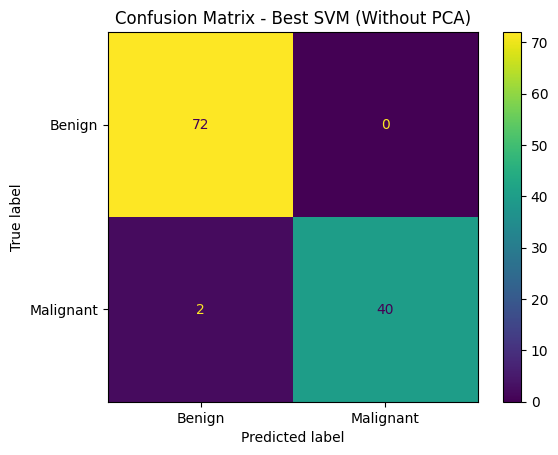

In [10]:
# CONFUSION MATRIX (BEST SVM WITHOUT PCA)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.svm import SVC
import matplotlib.pyplot as plt

# Best model based on your results
best_svm = SVC(kernel='rbf', C=10, gamma=0.01)

# Train on original (non-PCA) data
best_svm.fit(X_train, y_train)

# Predict
y_pred_best = best_svm.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_best)

# Display
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign', 'Malignant'])
disp.plot()

plt.title("Confusion Matrix - Best SVM (Without PCA)")
plt.show()

## 3.2 K-Nearest Neighbors (K-NN)

K-NN models are implemented with different values of K to determine the optimal number of neighbors.

In [11]:
# KNN


from sklearn.neighbors import KNeighborsClassifier

K_values = [3, 5, 7]

for k in K_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    acc, prec, rec, f1 = evaluate_model(y_test, y_pred)

    print(f"\nKNN (K={k})")
    print("Accuracy:", acc)
    print("Precision:", prec)
    print("Recall:", rec)
    print("F1 Score:", f1)


KNN (K=3)
Accuracy: 0.9385964912280702
Precision: 0.972972972972973
Recall: 0.8571428571428571
F1 Score: 0.9113924050632911

KNN (K=5)
Accuracy: 0.956140350877193
Precision: 0.9743589743589743
Recall: 0.9047619047619048
F1 Score: 0.9382716049382716

KNN (K=7)
Accuracy: 0.956140350877193
Precision: 0.9743589743589743
Recall: 0.9047619047619048
F1 Score: 0.9382716049382716


# Task 4: Data Classification after Feature Reduction

In this task, PCA is used to reduce the number of features, and classification models are trained again using the reduced dataset. The results are then compared with those obtained without PCA.

## 4.1 Feature Reduction using PCA

The number of principal components is selected based on the scree plot to retain most of the variance in the dataset.

In [12]:
# SELECT NUMBER OF COMPONENTS


import numpy as np

# Calculate cumulative variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Print to see how many components we need
for i, var in enumerate(cumulative_variance):
    print(f"Components: {i+1}, Cumulative Variance: {var:.4f}")

Components: 1, Cumulative Variance: 0.4427
Components: 2, Cumulative Variance: 0.6324
Components: 3, Cumulative Variance: 0.7264
Components: 4, Cumulative Variance: 0.7924
Components: 5, Cumulative Variance: 0.8473
Components: 6, Cumulative Variance: 0.8876
Components: 7, Cumulative Variance: 0.9101
Components: 8, Cumulative Variance: 0.9260
Components: 9, Cumulative Variance: 0.9399
Components: 10, Cumulative Variance: 0.9516
Components: 11, Cumulative Variance: 0.9614
Components: 12, Cumulative Variance: 0.9701
Components: 13, Cumulative Variance: 0.9781
Components: 14, Cumulative Variance: 0.9834
Components: 15, Cumulative Variance: 0.9865
Components: 16, Cumulative Variance: 0.9892
Components: 17, Cumulative Variance: 0.9911
Components: 18, Cumulative Variance: 0.9929
Components: 19, Cumulative Variance: 0.9945
Components: 20, Cumulative Variance: 0.9956
Components: 21, Cumulative Variance: 0.9966
Components: 22, Cumulative Variance: 0.9975
Components: 23, Cumulative Variance: 0.99

In [13]:
# Choose number of components
n_components = 7

pca_reduced = PCA(n_components=n_components)

X_pca_reduced = pca_reduced.fit_transform(X_scaled)

In [14]:
# SPLIT PCA DATA


X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca_reduced,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train_pca.shape)
print("Testing set:", X_test_pca.shape)

Training set: (455, 7)
Testing set: (114, 7)


LINEAR SVM WITH PCA

Linear SVM (C=2)
Accuracy: 0.9649122807017544
Precision: 0.9523809523809523
Recall: 0.9523809523809523
F1 Score: 0.9523809523809523


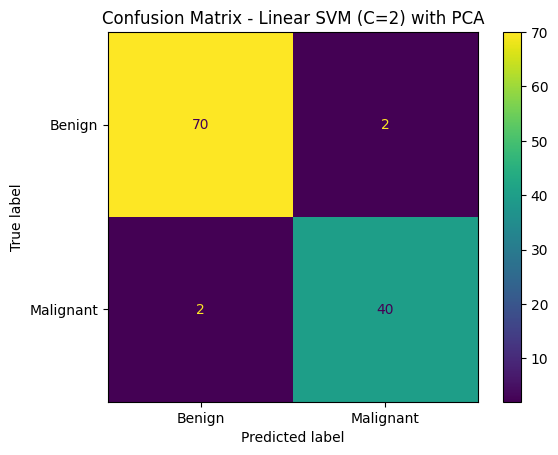


Linear SVM (C=10)
Accuracy: 0.9736842105263158
Precision: 0.975609756097561
Recall: 0.9523809523809523
F1 Score: 0.963855421686747


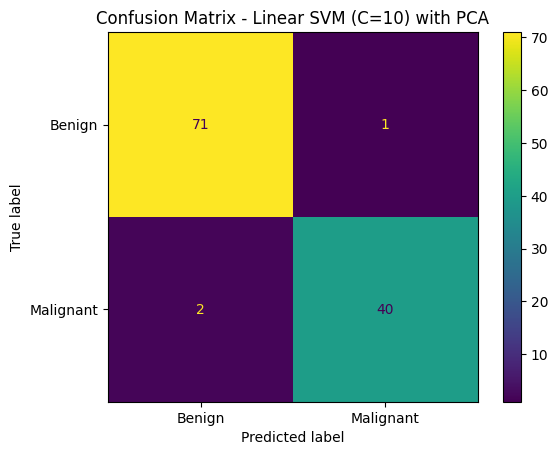


Linear SVM (C=50)
Accuracy: 0.9736842105263158
Precision: 0.975609756097561
Recall: 0.9523809523809523
F1 Score: 0.963855421686747


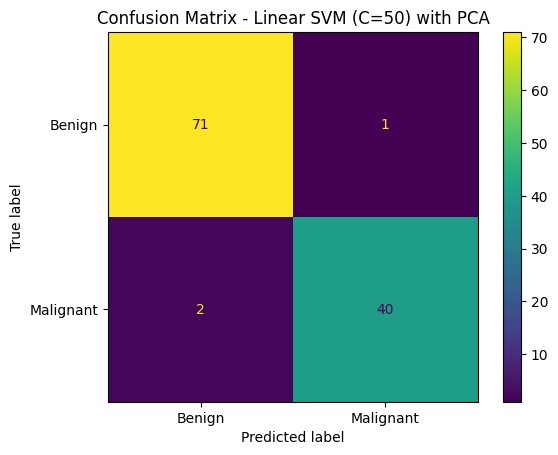

In [15]:
# SVM WITH PCA (Linear)


from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("LINEAR SVM WITH PCA")

C_values = [2, 10, 50]

for C in C_values:
    model = SVC(kernel='linear', C=C)
    model.fit(X_train_pca, y_train_pca)
    y_pred = model.predict(X_test_pca)
    acc, prec, rec, f1 = evaluate_model(y_test_pca, y_pred)

    print(f"\nLinear SVM (C={C})")
    print("Accuracy:", acc)
    print("Precision:", prec)
    print("Recall:", rec)
    print("F1 Score:", f1)

    cm = confusion_matrix(y_test_pca, y_pred, labels=['Benign', 'Malignant'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign', 'Malignant'])
    disp.plot()
    plt.title(f"Confusion Matrix - Linear SVM (C={C}) with PCA")
    plt.show()



RBF SVM WITH PCA

RBF SVM (C=2, gamma=0.01)
Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
F1 Score: 0.9512195121951219


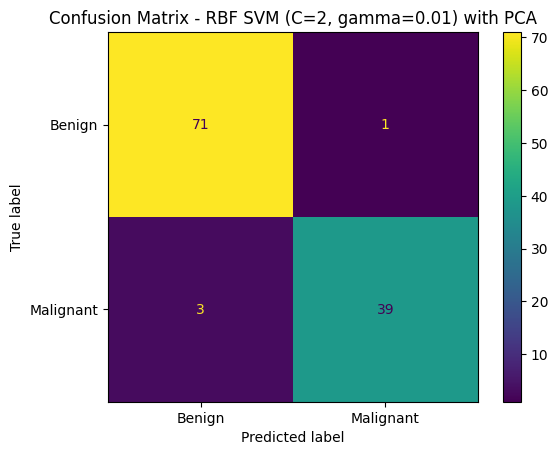


RBF SVM (C=2, gamma=0.1)
Accuracy: 0.9649122807017544
Precision: 0.9523809523809523
Recall: 0.9523809523809523
F1 Score: 0.9523809523809523


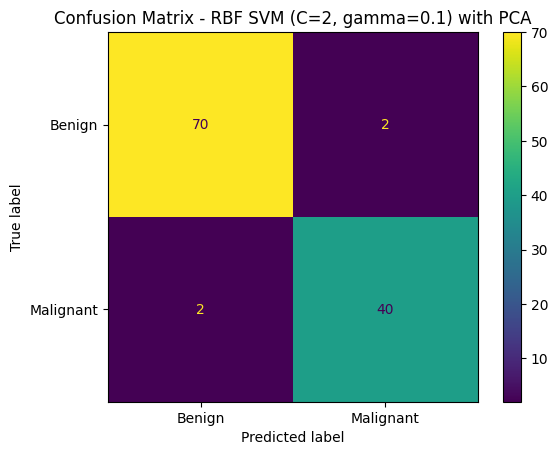


RBF SVM (C=2, gamma=1)
Accuracy: 0.7280701754385965
Precision: 1.0
Recall: 0.2619047619047619
F1 Score: 0.41509433962264153


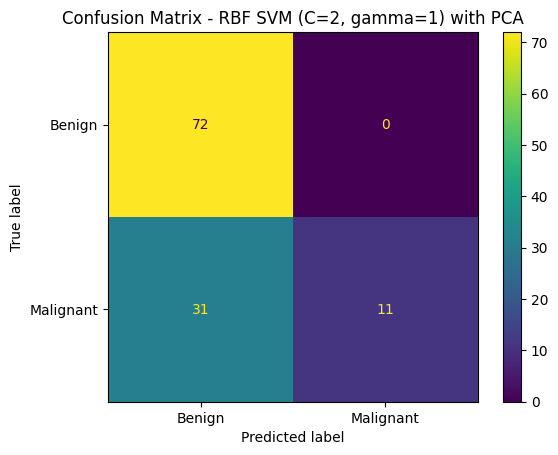


RBF SVM (C=10, gamma=0.01)
Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1 Score: 0.9629629629629629


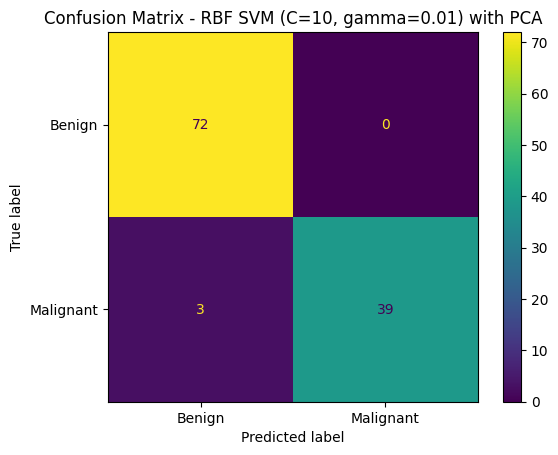


RBF SVM (C=10, gamma=0.1)
Accuracy: 0.9298245614035088
Precision: 0.9047619047619048
Recall: 0.9047619047619048
F1 Score: 0.9047619047619048


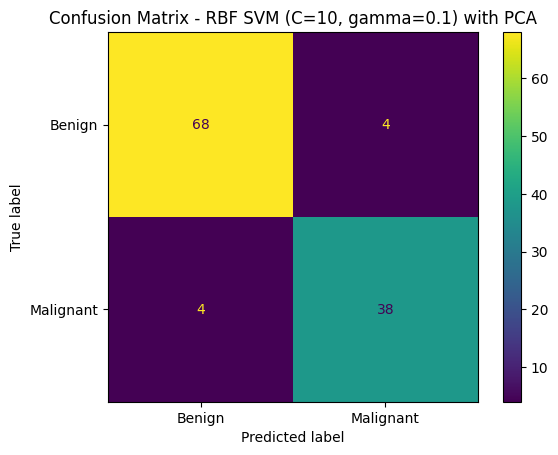


RBF SVM (C=10, gamma=1)
Accuracy: 0.7280701754385965
Precision: 1.0
Recall: 0.2619047619047619
F1 Score: 0.41509433962264153


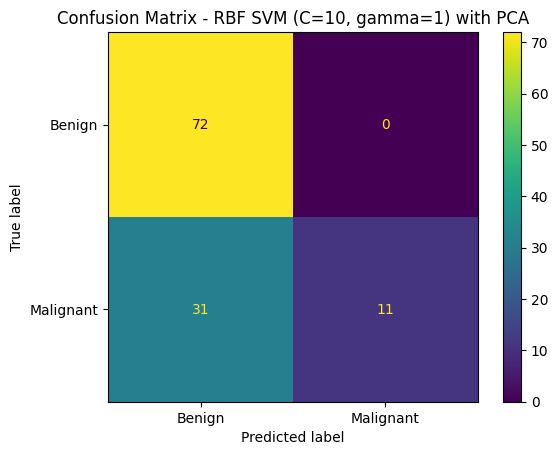


RBF SVM (C=50, gamma=0.01)
Accuracy: 0.9824561403508771
Precision: 1.0
Recall: 0.9523809523809523
F1 Score: 0.975609756097561


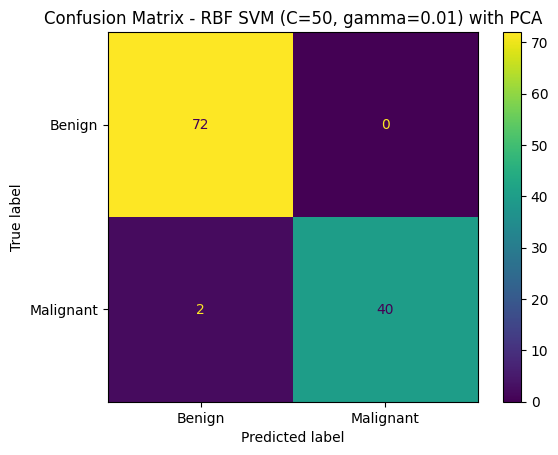


RBF SVM (C=50, gamma=0.1)
Accuracy: 0.8859649122807017
Precision: 0.8222222222222222
Recall: 0.8809523809523809
F1 Score: 0.8505747126436781


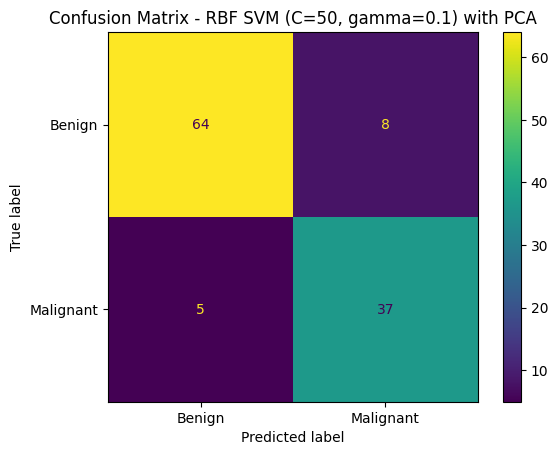


RBF SVM (C=50, gamma=1)
Accuracy: 0.7280701754385965
Precision: 1.0
Recall: 0.2619047619047619
F1 Score: 0.41509433962264153


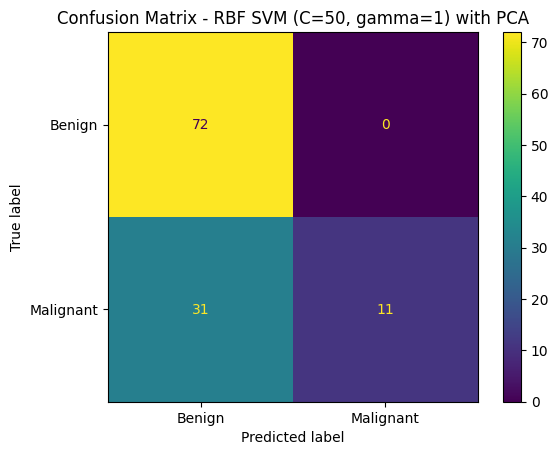

In [16]:
# SVM WITH PCA (RBF)

print("RBF SVM WITH PCA")

gamma_values = [0.01, 0.1, 1]

for C in C_values:
    for gamma in gamma_values:
        model = SVC(kernel='rbf', C=C, gamma=gamma)
        model.fit(X_train_pca, y_train_pca)
        y_pred = model.predict(X_test_pca)
        acc, prec, rec, f1 = evaluate_model(y_test_pca, y_pred)

        print(f"\nRBF SVM (C={C}, gamma={gamma})")
        print("Accuracy:", acc)
        print("Precision:", prec)
        print("Recall:", rec)
        print("F1 Score:", f1)

        cm = confusion_matrix(y_test_pca, y_pred, labels=['Benign', 'Malignant'])
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign', 'Malignant'])
        disp.plot()
        plt.title(f"Confusion Matrix - RBF SVM (C={C}, gamma={gamma}) with PCA")
        plt.show()

KNN with PCA

KNN (K=3)
Accuracy: 0.9473684210526315
Precision: 0.9736842105263158
Recall: 0.8809523809523809
F1 Score: 0.925


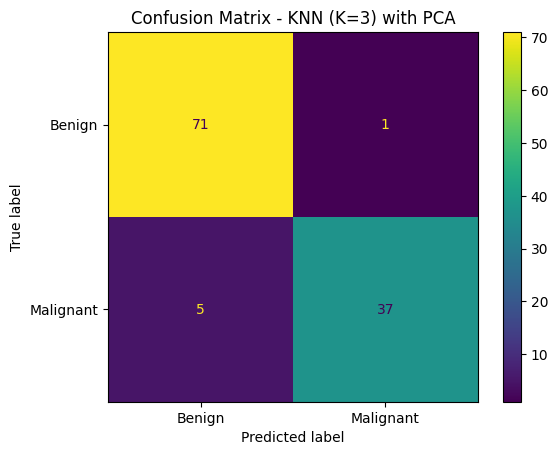


KNN (K=5)
Accuracy: 0.956140350877193
Precision: 0.9743589743589743
Recall: 0.9047619047619048
F1 Score: 0.9382716049382716


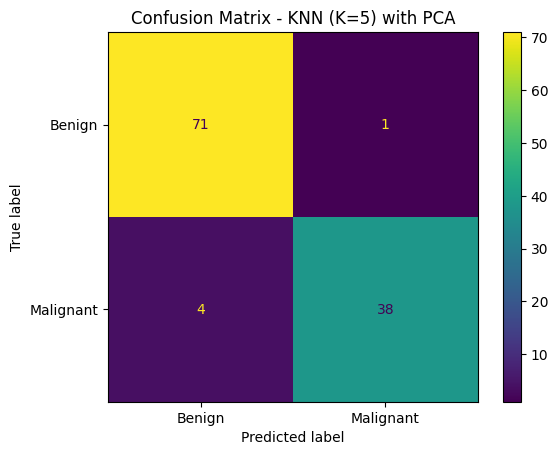


KNN (K=7)
Accuracy: 0.9473684210526315
Precision: 0.9736842105263158
Recall: 0.8809523809523809
F1 Score: 0.925


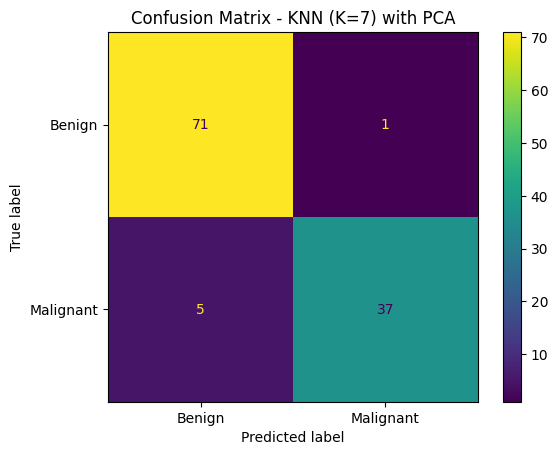

In [17]:
# KNN WITH PCA


print("KNN with PCA")

K_values = [3, 5, 7]

for k in K_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_pca, y_train_pca)
    y_pred = model.predict(X_test_pca)
    acc, prec, rec, f1 = evaluate_model(y_test_pca, y_pred)

    print(f"\nKNN (K={k})")
    print("Accuracy:", acc)
    print("Precision:", prec)
    print("Recall:", rec)
    print("F1 Score:", f1)

    cm = confusion_matrix(y_test_pca, y_pred, labels=['Benign', 'Malignant'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign', 'Malignant'])
    disp.plot()
    plt.title(f"Confusion Matrix - KNN (K={k}) with PCA")
    plt.show()